# EXTRA — Classificação de lesões mamárias em mamografias com CNN (CBIS-DDSM)

**Tech Challenge — Fase 1 (parte bônus)**

Na parte principal do projeto, o diagnóstico foi feito com **dados tabulares** (medidas extraídas das células). Aqui fazemos o mesmo diagnóstico, **benigno ou maligno**, mas direto a partir de **imagens de mamografia**, usando uma **rede neural convolucional (CNN)**.

**Dataset:** [CBIS-DDSM no Kaggle](https://www.kaggle.com/datasets/awsaf49/cbis-ddsm-breast-cancer-image-dataset/data)

**Estratégia:**
1. Usar os **recortes da lesão** (*cropped images*) em vez da mamografia inteira. O recorte foca na região de interesse e torna o problema viável com poucos milhares de imagens.
2. **Transfer learning** com a **EfficientNetB0**, uma rede pré-treinada no ImageNet. A rede já sabe reconhecer bordas, texturas e formas, e só precisamos ensiná-la a diferenciar lesões.
3. Separação **treino / validação / teste** sem misturar pacientes entre os conjuntos.
4. Avaliação com **recall, F1 e AUC**, com o mesmo raciocínio da parte tabular: o pior erro é deixar passar um caso maligno.
5. **Grad-CAM** para mostrar em que região da imagem a rede "olhou" para decidir. É o equivalente visual do SHAP.

> ⚙️ Antes de rodar: **Ambiente de execução → Alterar o tipo de ambiente de execução → GPU (T4)**.

## 1. Configuração do ambiente

In [18]:
import os, glob, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras import layers
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, recall_score,
                             precision_score, f1_score, accuracy_score)

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
OUTPUT_DIR = "/content/outputs_cnn"
os.makedirs(OUTPUT_DIR, exist_ok=True)

keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")

print("TensorFlow:", tf.__version__)
print("GPU disponível:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download do dataset

O `kagglehub` já vem instalado no Colab. O download tem alguns GB e leva alguns minutos.

Se aparecer um **erro de autenticação**, descomente a linha `kagglehub.login()`, rode a célula de novo e informe seu usuário e a sua chave da API do Kaggle. A chave fica em *kaggle.com → Settings → API → Create New Token*.

In [19]:
import kagglehub
# kagglehub.login()

DATA_ROOT = kagglehub.dataset_download("awsaf49/cbis-ddsm-breast-cancer-image-dataset")
print("Dataset em:", DATA_ROOT)
print(os.listdir(DATA_ROOT))

Using Colab cache for faster access to the 'cbis-ddsm-breast-cancer-image-dataset' dataset.
Dataset em: /kaggle/input/cbis-ddsm-breast-cancer-image-dataset
['jpeg', 'csv']


## 3. Ligando os diagnósticos às imagens

O dataset tem duas partes:
- **CSVs de casos** (`mass_case_description_*.csv` e `calc_case_description_*.csv`): uma linha por lesão, com o diagnóstico (`pathology`) e o caminho original do recorte, em formato DICOM;
- **pasta `jpeg/`**: as imagens convertidas para JPEG, organizadas por um código chamado *SeriesInstanceUID*.

O arquivo `dicom_info.csv` liga as duas partes. Ele diz qual JPEG corresponde a cada série e qual é o tipo de imagem. Como algumas séries guardam juntos o recorte e a máscara da lesão, filtramos apenas as linhas de *cropped images*.

**Rótulo:** `MALIGNANT` = 1. `BENIGN` e `BENIGN_WITHOUT_CALLBACK` = 0.

In [3]:
def find_file(name):
    hits = glob.glob(os.path.join(DATA_ROOT, "**", name), recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} não encontrado em {DATA_ROOT}")
    return hits[0]

def resolve_jpeg(image_path):
    # dicom_info traz caminhos como 'CBIS-DDSM/jpeg/<uid>/1-1.jpg'
    relative = str(image_path).split("CBIS-DDSM/", 1)[-1]
    return os.path.join(DATA_ROOT, relative)

# --- Mapa SeriesInstanceUID -> JPEG do recorte ---
dicom_info = pd.read_csv(find_file("dicom_info.csv"))
crops = dicom_info[dicom_info["SeriesDescription"] == "cropped images"].copy()
crops["caminho"] = crops["image_path"].map(resolve_jpeg)
crop_map = (crops.drop_duplicates("SeriesInstanceUID")
                 .set_index("SeriesInstanceUID")["caminho"])
print(f"Recortes listados no dicom_info: {len(crop_map)}")

# --- CSVs de casos ---
def load_cases(pattern, split):
    frames = []
    for file in sorted(glob.glob(os.path.join(DATA_ROOT, "**", pattern), recursive=True)):
        df = pd.read_csv(file)
        df["tipo"] = "massa" if "mass" in os.path.basename(file) else "calcificação"
        frames.append(df)
    cases = pd.concat(frames, ignore_index=True)
    cases["conjunto"] = split
    return cases

cases = pd.concat([
    load_cases("*case_description_train_set.csv", "treino"),
    load_cases("*case_description_test_set.csv", "teste"),
], ignore_index=True)

# O caminho original é <pasta>/<StudyUID>/<SeriesUID>/arquivo.dcm.
# Testamos as duas posições de UID e ficamos com a que encontra mais imagens.
parts = cases["cropped image file path"].astype(str).str.strip().str.split("/")
best = max([1, 2], key=lambda i: parts.str[i].isin(crop_map.index).sum())
cases["series_uid"] = parts.str[best]
cases["caminho"] = cases["series_uid"].map(crop_map)

cases["maligno"] = (cases["pathology"].str.strip() == "MALIGNANT").astype(int)

total = len(cases)
cases = cases.dropna(subset=["caminho"])
cases = cases[cases["caminho"].map(os.path.exists)].reset_index(drop=True)
print(f"Lesões nos CSVs: {total} | com imagem encontrada: {len(cases)}")

df = cases[["patient_id", "tipo", "pathology", "maligno", "conjunto", "caminho"]]
df.head()

Recortes listados no dicom_info: 3567
Lesões nos CSVs: 3568 | com imagem encontrada: 3566


,patient_id,tipo,pathology,maligno,conjunto,caminho
0,P_00005,calcificação,MALIGNANT,1,treino,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
1,P_00005,calcificação,MALIGNANT,1,treino,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
2,P_00007,calcificação,BENIGN,0,treino,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
3,P_00007,calcificação,BENIGN,0,treino,/kaggle/input/cbis-ddsm-breast-cancer-image-da...
4,P_00008,calcificação,BENIGN_WITHOUT_CALLBACK,0,treino,/kaggle/input/cbis-ddsm-breast-cancer-image-da...


## 4. Exploração dos dados

diagnostico            Benigno  Maligno
conjunto tipo                          
teste    calcificação      197      129
         massa             231      147
treino   calcificação     1001      543
         massa             681      637

Proporção de malignos: 40.8 %


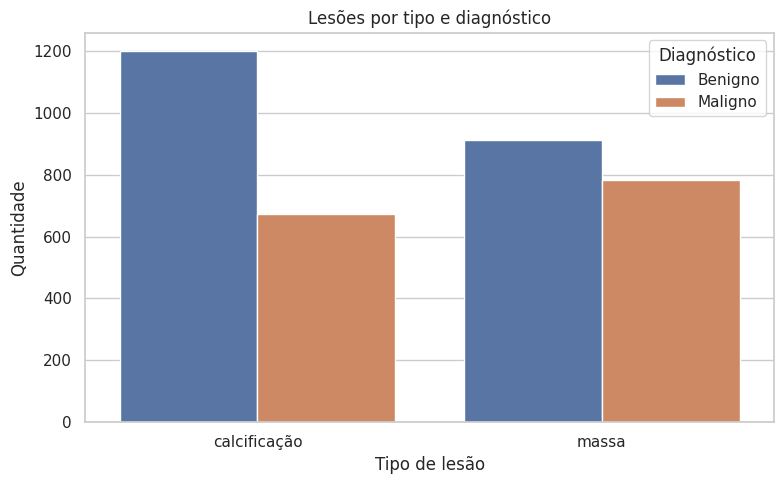

In [4]:
resumo = (df.assign(diagnostico=df["maligno"].map({0: "Benigno", 1: "Maligno"}))
            .groupby(["conjunto", "tipo", "diagnostico"]).size()
            .unstack(fill_value=0))
print(resumo)
print("\nProporção de malignos:", round(df["maligno"].mean() * 100, 1), "%")

plt.figure(figsize=(8, 5))
sns.countplot(data=df.assign(Diagnóstico=df["maligno"].map({0: "Benigno", 1: "Maligno"})),
              x="tipo", hue="Diagnóstico", hue_order=["Benigno", "Maligno"])
plt.title("Lesões por tipo e diagnóstico")
plt.xlabel("Tipo de lesão")
plt.ylabel("Quantidade")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/distribuicao_classes.png", dpi=200)
plt.show()

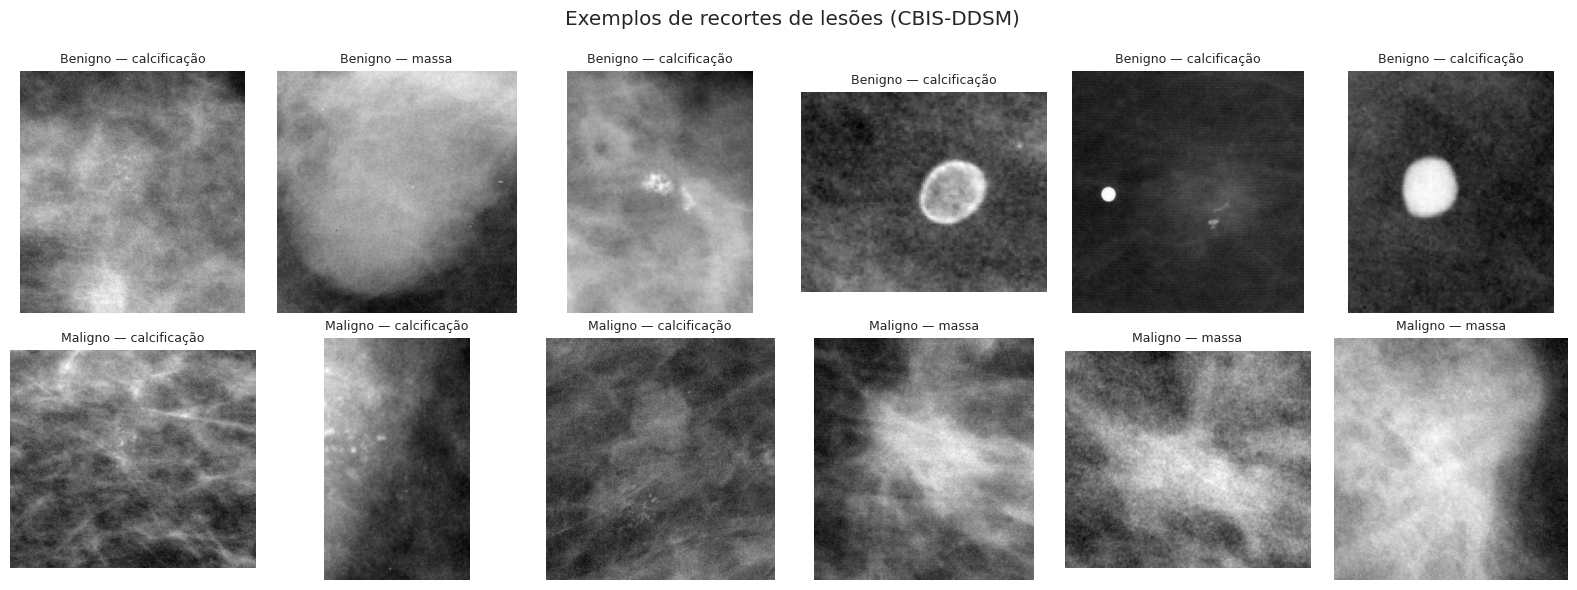

In [5]:
# Exemplos de recortes: linha de cima benignos, linha de baixo malignos
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for row, label in enumerate([0, 1]):
    sample = df[df["maligno"] == label].sample(6, random_state=SEED)
    for ax, (_, r) in zip(axes[row], sample.iterrows()):
        ax.imshow(plt.imread(r["caminho"]), cmap="gray")
        ax.set_title(f"{'Maligno' if label else 'Benigno'} — {r['tipo']}", fontsize=9)
        ax.axis("off")
plt.suptitle("Exemplos de recortes de lesões (CBIS-DDSM)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/exemplos_imagens.png", dpi=200)
plt.show()

## 5. Separação treino / validação / teste

- **Teste:** a divisão oficial de teste do CBIS-DDSM, usada uma única vez no final.
- **Treino e validação:** os casos de treino oficiais são divididos em 80% e 20% **por paciente** (`GroupShuffleSplit`). Assim, as lesões de uma mesma paciente nunca aparecem ao mesmo tempo no treino e na validação. Se aparecessem, a validação ficaria otimista demais, porque a rede reconheceria a paciente em vez de aprender o padrão da lesão.

In [6]:
train_full = df[df["conjunto"] == "treino"].reset_index(drop=True)
test_df = df[df["conjunto"] == "teste"].reset_index(drop=True)

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, val_idx = next(gss.split(train_full, groups=train_full["patient_id"]))
train_df = train_full.iloc[train_idx].reset_index(drop=True)
val_df = train_full.iloc[val_idx].reset_index(drop=True)

assert not set(train_df["patient_id"]) & set(val_df["patient_id"]), "Paciente repetido!"

for name, part in [("Treino", train_df), ("Validação", val_df), ("Teste", test_df)]:
    print(f"{name:10s}: {len(part):5d} imagens | {part['maligno'].mean()*100:4.1f}% malignos")

Treino    :  2277 imagens | 41.2% malignos
Validação :   585 imagens | 41.5% malignos
Teste     :   704 imagens | 39.2% malignos


## 6. Pipeline de imagens (`tf.data`)

Cada imagem é lida, convertida para 3 canais (a EfficientNet espera imagens RGB) e redimensionada para 224×224. O `cache()` guarda as imagens na memória depois da primeira época, o que acelera o treino.

A EfficientNet do Keras já faz a própria normalização internamente. Por isso as imagens entram com valores de 0 a 255.

In [7]:
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["caminho"].values, frame["maligno"].values.astype("float32")))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(1024, seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)   # sem shuffle: a ordem bate com test_df

## 7. Modelo: EfficientNetB0 com transfer learning

- **Aumento de dados:** giros, rotações, zoom e contraste aleatórios, aplicados só no treino. Isso ajuda a reduzir o overfitting em um dataset pequeno.
- **Base:** EfficientNetB0 pré-treinada no ImageNet e **congelada** na primeira fase.
- **Classificador:** pooling global, dropout e um neurônio sigmoide, que dá a probabilidade de a lesão ser maligna.
- **Pesos de classe:** compensam o fato de haver mais lesões benignas do que malignas.

In [8]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="aumento_de_dados")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

classifier_head = keras.Sequential([
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
], name="classificador")

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)
x = base_model(x, training=False)
outputs = classifier_head(x)
model = keras.Model(inputs, outputs, name="cnn_cbis_ddsm")

METRICS = [
    keras.metrics.BinaryAccuracy(name="accuracy"),
    keras.metrics.AUC(name="auc"),
    keras.metrics.Recall(name="recall"),
    keras.metrics.Precision(name="precision"),
]

weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=train_df["maligno"])
class_weight = {0: weights[0], 1: weights[1]}
print("Pesos de classe:", class_weight)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Pesos de classe: {0: np.float64(0.8496268656716418), 1: np.float64(1.2150480256136607)}


Model: "cnn_cbis_ddsm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_de_dados (Sequential)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classificador (Sequential)      │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 8. Treinamento — fase 1 (base congelada)

In [9]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=4,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5,
                                      patience=2, min_lr=1e-7),
]

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=METRICS)

history_1 = model.fit(train_ds, validation_data=val_ds, epochs=15,
                      class_weight=class_weight, callbacks=callbacks)

Epoch 1/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 36s 225ms/step - accuracy: 0.5920 - auc: 0.6435 - loss: 0.6560 - precision: 0.5035 - recall: 0.6073 - val_accuracy: 0.6444 - val_auc: 0.7003 - val_loss: 0.6132 - val_precision: 0.6423 - val_recall: 0.3251 - learning_rate: 0.0010
Epoch 2/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 95ms/step - accuracy: 0.6372 - auc: 0.7048 - loss: 0.6193 - precision: 0.5486 - recall: 0.6692 - val_accuracy: 0.6308 - val_auc: 0.7108 - val_loss: 0.6127 - val_precision: 0.5452 - val_recall: 0.6708 - learning_rate: 0.0010
Epoch 3/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 96ms/step - accuracy: 0.6465 - auc: 0.7167 - loss: 0.6107 - precision: 0.5573 - recall: 0.6852 - val_accuracy: 0.6462 - val_auc: 0.7201 - val_loss: 0.5987 - val_precision: 0.5672 - val_recall: 0.6255 - learning_rate: 0.0010
Epoch 4/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 95ms/step - accuracy: 0.6487 - auc: 0.7144 - loss: 0.6122 - precision: 0.5589 - recall: 0.6937 - val_accuracy: 0.6239 - val_auc: 0.7273 - val_loss: 0.5993 - val_p

## 9. Treinamento — fase 2 (*fine-tuning*)

Agora liberamos as **últimas 40 camadas** da EfficientNet para que elas se ajustem às mamografias. A taxa de aprendizado é bem menor, para não estragar o que a rede já sabe. As camadas de *BatchNormalization* continuam congeladas, o que é a prática recomendada no fine-tuning.

In [10]:
base_model.trainable = True
for layer in base_model.layers[:-40]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="binary_crossentropy", metrics=METRICS)

history_2 = model.fit(train_ds, validation_data=val_ds, epochs=15,
                      class_weight=class_weight, callbacks=callbacks)

Epoch 1/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 22s 152ms/step - accuracy: 0.6827 - auc: 0.7614 - loss: 0.5706 - precision: 0.6006 - recall: 0.6881 - val_accuracy: 0.6991 - val_auc: 0.7551 - val_loss: 0.5607 - val_precision: 0.6683 - val_recall: 0.5473 - learning_rate: 1.0000e-05
Epoch 2/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 8s 112ms/step - accuracy: 0.6957 - auc: 0.7694 - loss: 0.5657 - precision: 0.6117 - recall: 0.7129 - val_accuracy: 0.6769 - val_auc: 0.7575 - val_loss: 0.5634 - val_precision: 0.6063 - val_recall: 0.6337 - learning_rate: 1.0000e-05
Epoch 3/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 8s 112ms/step - accuracy: 0.6820 - auc: 0.7651 - loss: 0.5712 - precision: 0.5913 - recall: 0.7364 - val_accuracy: 0.6923 - val_auc: 0.7611 - val_loss: 0.5557 - val_precision: 0.6583 - val_recall: 0.5391 - learning_rate: 1.0000e-05
Epoch 4/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 8s 112ms/step - accuracy: 0.6983 - auc: 0.7739 - loss: 0.5610 - precision: 0.6143 - recall: 0.7172 - val_accuracy: 0.6974 - val_auc: 0.7634 - val_loss:

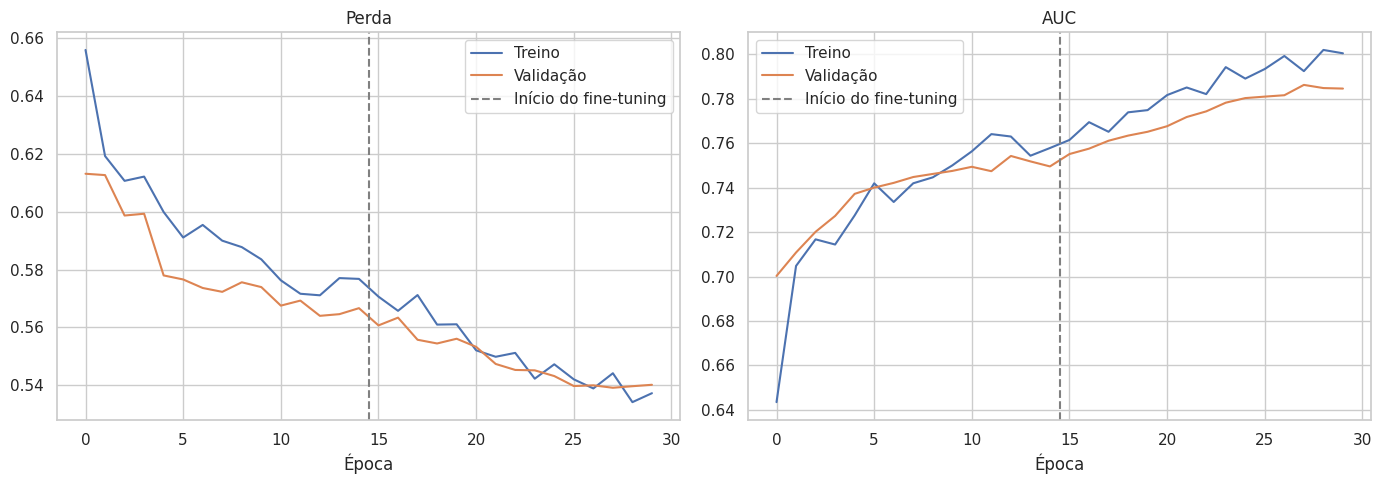

In [11]:
# Curvas de aprendizado das duas fases juntas
hist = {k: history_1.history[k] + history_2.history.get(k, [])
        for k in history_1.history}
fase2_inicio = len(history_1.history["loss"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [(axes[0], "loss", "Perda"), (axes[1], "auc", "AUC")]:
    ax.plot(hist[metric], label="Treino")
    ax.plot(hist[f"val_{metric}"], label="Validação")
    ax.axvline(fase2_inicio - 0.5, color="gray", linestyle="--", label="Início do fine-tuning")
    ax.set_title(title)
    ax.set_xlabel("Época")
    ax.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/curvas_treinamento.png", dpi=200)
plt.show()

## 10. Escolha do limiar de decisão (na validação)

Por padrão, a rede classifica como maligno quando a probabilidade passa de 0,5. Em triagem, porém, é preferível **errar para o lado da cautela**. Por isso usamos a validação para escolher o **maior limiar que ainda garante recall ≥ 85%** para malignos. O conjunto de teste continua intocado.

In [12]:
TARGET_RECALL = 0.85

val_probs = model.predict(val_ds, verbose=0).ravel()
y_val = val_df["maligno"].values

fpr, tpr, thresholds = roc_curve(y_val, val_probs)
idx = np.argmax(tpr >= TARGET_RECALL)
threshold = float(min(thresholds[idx], 1.0))

print(f"AUC na validação: {roc_auc_score(y_val, val_probs):.4f}")
print(f"Limiar escolhido: {threshold:.3f} (recall na validação = {tpr[idx]:.3f})")

AUC na validação: 0.7862
Limiar escolhido: 0.274 (recall na validação = 0.856)


## 11. Avaliação final no conjunto de teste

In [13]:
test_probs = model.predict(test_ds, verbose=0).ravel()
y_test = test_df["maligno"].values
auc_test = roc_auc_score(y_test, test_probs)

results = []
for name, thr in [("Limiar 0,5", 0.5), (f"Limiar ajustado ({threshold:.3f})", threshold)]:
    pred = (test_probs >= thr).astype(int)
    results.append({
        "Limiar": name,
        "Acurácia": accuracy_score(y_test, pred),
        "Precisão (maligno)": precision_score(y_test, pred, zero_division=0),
        "Recall (maligno)": recall_score(y_test, pred, zero_division=0),
        "F1 (maligno)": f1_score(y_test, pred, zero_division=0),
    })
results = pd.DataFrame(results).set_index("Limiar").round(4)
print(f"AUC no teste: {auc_test:.4f}\n")
print(results)
results.to_csv(f"{OUTPUT_DIR}/metricas_teste.csv")

y_pred = (test_probs >= threshold).astype(int)
print("\nRelatório (limiar ajustado):")
print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"], digits=4))

AUC no teste: 0.7282

                         Acurácia  Precisão (maligno)  Recall (maligno)  \
Limiar                                                                    
Limiar 0,5                 0.6889              0.6213            0.5290   
Limiar ajustado (0.274)    0.5611              0.4688            0.8986   

                         F1 (maligno)  
Limiar                                 
Limiar 0,5                     0.5714  
Limiar ajustado (0.274)        0.6161  

Relatório (limiar ajustado):
              precision    recall  f1-score   support

     Benigno     0.8400    0.3435    0.4876       428
     Maligno     0.4688    0.8986    0.6161       276

    accuracy                         0.5611       704
   macro avg     0.6544    0.6210    0.5519       704
weighted avg     0.6945    0.5611    0.5380       704



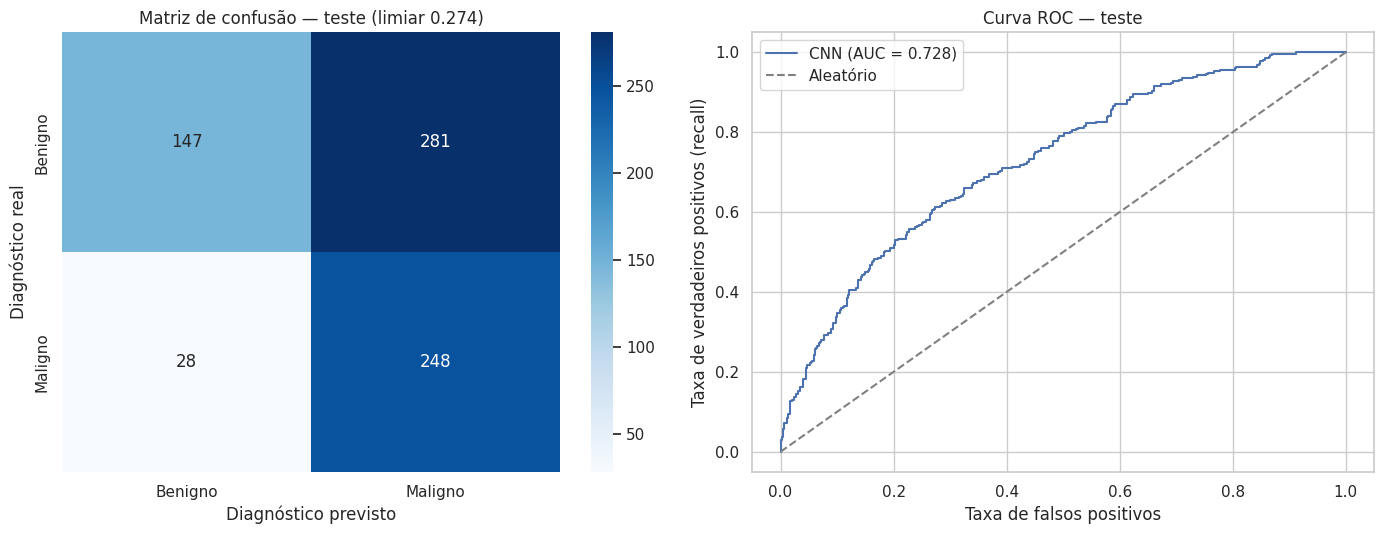

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Benigno", "Maligno"], yticklabels=["Benigno", "Maligno"], ax=axes[0])
axes[0].set_title(f"Matriz de confusão — teste (limiar {threshold:.3f})")
axes[0].set_xlabel("Diagnóstico previsto")
axes[0].set_ylabel("Diagnóstico real")

fpr_t, tpr_t, _ = roc_curve(y_test, test_probs)
axes[1].plot(fpr_t, tpr_t, label=f"CNN (AUC = {auc_test:.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Aleatório")
axes[1].set_title("Curva ROC — teste")
axes[1].set_xlabel("Taxa de falsos positivos")
axes[1].set_ylabel("Taxa de verdadeiros positivos (recall)")
axes[1].legend()

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/matriz_confusao_roc_cnn.png", dpi=200)
plt.show()

In [15]:
# Desempenho separado por tipo de lesão
for tipo in test_df["tipo"].unique():
    mask = (test_df["tipo"] == tipo).values
    print(f"{tipo:13s} | AUC = {roc_auc_score(y_test[mask], test_probs[mask]):.4f} "
          f"| Recall = {recall_score(y_test[mask], y_pred[mask]):.4f} | n = {mask.sum()}")

calcificação  | AUC = 0.7373 | Recall = 0.8605 | n = 326
massa         | AUC = 0.7299 | Recall = 0.9320 | n = 378


## 12. Interpretação com Grad-CAM

O **Grad-CAM** destaca as regiões da imagem que mais influenciaram a previsão: quanto mais quente a cor, maior a influência. Assim o médico pode conferir se a rede está olhando para a lesão ou para algo irrelevante, como uma borda ou uma marcação do filme.

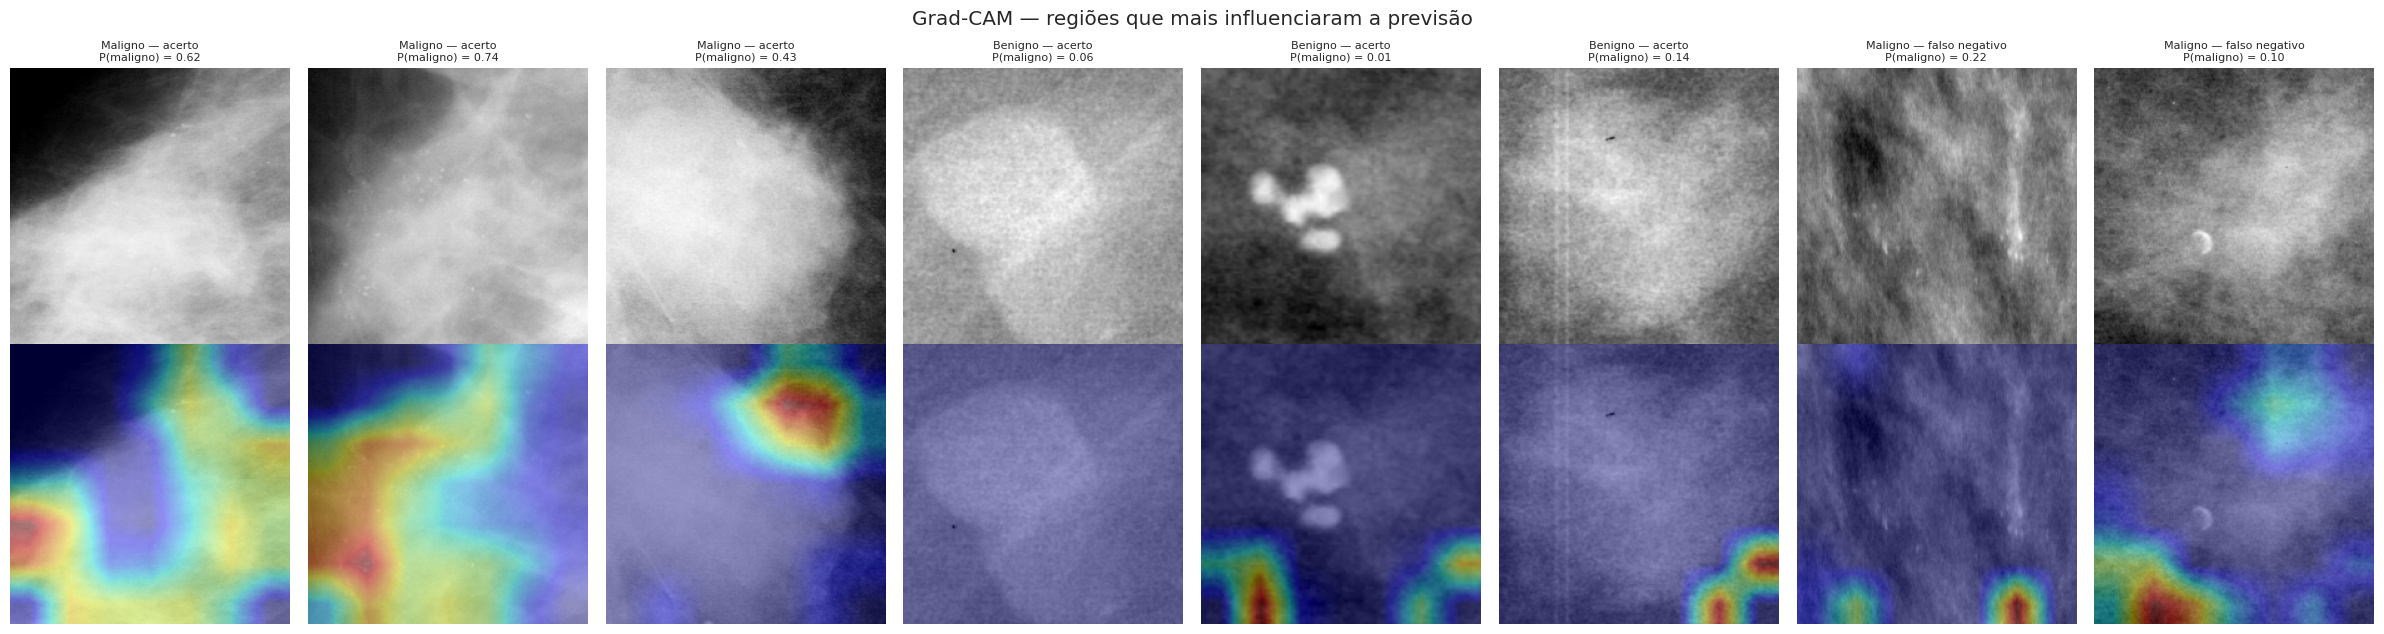

In [16]:
def grad_cam(image):
    img = tf.convert_to_tensor(image[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_maps = base_model(img, training=False)
        tape.watch(conv_maps)
        prob = classifier_head(conv_maps, training=False)[:, 0]
    grads = tape.gradient(prob, conv_maps)
    channel_weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv_maps[0] * channel_weights, axis=-1))
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE))[..., 0]
    return cam.numpy(), float(prob[0])

# Exemplos do teste: 3 malignos acertados, 3 benignos acertados e até 2 malignos que a rede deixou passar
test_df["prob"] = test_probs
test_df["pred"] = y_pred
grupos = [
    ("Maligno — acerto", test_df[(test_df.maligno == 1) & (test_df.pred == 1)], 3),
    ("Benigno — acerto", test_df[(test_df.maligno == 0) & (test_df.pred == 0)], 3),
    ("Maligno — falso negativo", test_df[(test_df.maligno == 1) & (test_df.pred == 0)], 2),
]
exemplos = [(titulo, r) for titulo, g, n in grupos
            for _, r in g.sample(min(n, len(g)), random_state=SEED).iterrows()]

fig, axes = plt.subplots(2, len(exemplos), figsize=(3 * len(exemplos), 6.5))
for col, (titulo, r) in enumerate(exemplos):
    image, _ = load_image(r["caminho"], 0)
    image = image.numpy()
    cam, prob = grad_cam(image)
    axes[0, col].imshow(image.astype("uint8"))
    axes[0, col].set_title(f"{titulo}\nP(maligno) = {prob:.2f}", fontsize=8)
    axes[1, col].imshow(image.astype("uint8"))
    axes[1, col].imshow(cam, cmap="jet", alpha=0.4)
    for ax in axes[:, col]:
        ax.axis("off")
plt.suptitle("Grad-CAM — regiões que mais influenciaram a previsão")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/grad_cam.png", dpi=200)
plt.show()

## 13. Salvando os resultados

Este passo gera um `.zip` com todos os gráficos e métricas. Coloque o conteúdo do arquivo na pasta `outputs/cnn/` do repositório e o notebook em `notebooks/`.

In [17]:
model.save(f"{OUTPUT_DIR}/cnn_cbis_ddsm.keras")

zip_path = "/content/resultados_cnn.zip"
with zipfile.ZipFile(zip_path, "w") as z:
    for file in os.listdir(OUTPUT_DIR):
        if not file.endswith(".keras"):   # o modelo é grande demais para o Git
            z.write(os.path.join(OUTPUT_DIR, file), arcname=file)

from google.colab import files
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Discussão (anote para o relatório)

- **Compare com a parte tabular.** A classificação por imagem é bem mais difícil. Na literatura, os modelos com recortes do CBIS-DDSM costumam ficar com **AUC entre 0,75 e 0,85**, contra mais de 0,99 no Wisconsin. Isso acontece porque o modelo tabular recebe medidas já extraídas por especialistas, enquanto a CNN precisa aprender sozinha o que observar.
- **Observe o desempenho por tipo de lesão:** massas e calcificações têm aparências muito diferentes.
- **Explique a escolha do limiar.** Baixar o limiar aumenta o recall, ou seja, deixa passar menos casos malignos, mas gera mais falsos positivos e, portanto, mais biópsias desnecessárias. Esse equilíbrio é uma decisão clínica.
- **Comente o Grad-CAM.** A rede olha para a lesão ou para as bordas do recorte? Isso ajuda a avaliar se o modelo é confiável.
- **Limitações:** o modelo usa recortes já marcados por radiologistas, então ainda não localiza a lesão sozinho na mamografia inteira. Além disso, o dataset é pequeno e vem de digitalizações de filmes antigos.
- **Uso na prática:** o modelo serviria como segunda leitura ou para priorizar casos na triagem. **A decisão final é sempre do médico.**